In [1]:
import numpy as np
from scipy import optimize
# get_ipython().run_line_magic('matplotlib', 'widget')
from dolfin import *
import matplotlib as mpl
import matplotlib.pyplot as plt
import os
from scipy.optimize import curve_fit
import pandas as pd
from matplotlib.pyplot import cm
from scipy.spatial import ConvexHull, convex_hull_plot_2d
import shapely
from shapely import Polygon, Point
from matplotlib.collections import LineCollection
import re
from scipy import stats
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.interpolate import CubicSpline
from numpy import linalg
import yt
from numpy import inf

/Users/laurenyan/opt/anaconda3/envs/fungi_surrogate_env/lib/python3.14/site-packages/ufl/__init__.py:250: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
def sigmoid_r(r, K, L, r0):
    return K / (1 + np.exp(-L * (r0 - r)))

def sigmoid_t(t, K, L, tn):
    return K / (1 + np.exp(L * (tn - t)))

def initial_pulse(r, A, s, r0):
    return A * np.exp(-s * np.abs(r - r0) ** 2)

def tolerant_mean(arrs):
    lens = [len(i) for i in arrs]
    arr = np.ma.empty((np.max(lens),len(arrs)))
    arr.mask = True
    for idx, l in enumerate(arrs):
        arr[:len(l),idx] = l
    return arr.mean(axis = -1), arr.std(axis=-1)

def round_to_multiple(number, multiple):
    return multiple * np.round(number / multiple)

In [3]:
def PDE(pars, upar, time, plot):
    '''
    pars = dictionary of parameters to fit (key = parameter name, value = parameter value).
    fix_mode = parameter to fix and minimize around
    fix = value to fix the fixed parameter at
    time = hours
    upar = parameters of initial condition [A, s, r0]
    '''
    alphval = pars[0]
    beta = Constant(pars[1])
    v_sval = pars[2]
    s_scal =  Constant(pars[3])
    D = Constant(pars[4])

    # Define the problem
    Length = 3 # 40.0
    left = 1e-3
    dX = 0.01
    X = np.arange(left, Length, dX)
    nx = len(X)
    nT = int(time * 10) # 900
    keep = 10 # get every hour
    mesh = IntervalMesh(nx, left, Length)
    P1 = FiniteElement('P', interval, 1)
    element = MixedElement([P1, P1])
    V = FunctionSpace(mesh, element)
    cmap2 = mpl.colormaps["spring"]
    cmap = mpl.colormaps["winter"]
    set_log_level(LogLevel.WARNING)

    density_tip_t = np.zeros((int(nT / keep), nx))
    density_in_t = np.zeros((int(nT / keep), nx))
    n_sat_r = []
    rho_sat_r = []
    x_r = []

    # Define the parameters
    T = time # 90
    dt = T/nT
    # alphval = 0.039
    cval = 0.6
    # Define the initial condition
    u0_str = str(upar[0]) + '*exp(-0.5*' + str(upar[1]) + '*pow(abs(x[0]-' + str(upar[2]) + '),2))'
    u0 = Expression((u0_str, '0.0'), degree=1)
    #define radial coordinate
    rexp = Expression(('1.0/x[0]', '0.0'), degree=1)
    r = interpolate(rexp, V)
    invr, _ = split(r)
    # Define other elements

    u_n = interpolate(u0, V)
    u = Function (V)
    n, rho = split(u)
    n_n, rho_n= split(u_n)
    v_1, v_2 = TestFunctions(V)
    k = Constant((1,))

    # s_scal =  Constant(0.0288) # Constant(0.2)
    # beta = Constant(0.022)
    alpha = Constant(alphval)
    # D = Constant(0.02)

    n_mid = 0.5*(n_n + n)
    # v_sval = 0.235
    v_s = Constant((v_sval,))

    F = n * v_1 * dx - n_n * v_1 * dx
    # Diffusion term
    F += D * dot(grad(n), grad(v_1)) * dt * dx
    # Cylindrical correction terms using invr
    F += invr * D * dot(grad(n), Constant((1.0,))) * v_1 * dt * dx
    F += dt * dot(grad(n_mid), v_s) * v_1 * dx
    F += invr * dt * n_mid * Constant(v_sval) * v_1 * dx

    F -= dt * s_scal * n * v_2 * dx - (rho - rho_n) * v_2 * dx
    F += beta * v_1 * rho * n * dt * dx
    F -= alpha * n * v_1 * dt * dx

    # Apply the boundary conditions (left=left, right=Length)
    u_L = (Constant(0.0), Constant(0.0))
    u_R = (Constant(0.0), Constant(0.0))
    bc_L = DirichletBC(V, u_L, f'near(x[0], {left})')
    bc_R = DirichletBC(V, u_R, f'near(x[0], {Length})')
    bcs = [bc_L, bc_R]

    t = 0.0
    a, L = lhs(F), rhs(F)
    V2 = FunctionSpace(mesh, 'P', 1)
    # X = np.arange(left, Length, dx)
    poss = []

    i=0

    if plot == 1:
        fig, axs = plt.subplots(3, 1)
    for t in np.linspace(0,T,nT):
        try:
            solve(F==0, u,bcs)
            u_n.assign(u)
            _n, _rho= u.split()

            if i%keep==0:# i%100==0:
                n_field = interpolate(_n, V2)
                rho_field = interpolate(_rho, V2)
                density_tip_t[int(i / keep), :] = [n_field(x) for x in X]
                density_in_t[int(i / keep), :] = [rho_field(x) for x in X]
                poss.append(np.argmax([n_field(x) for x in X]))
                if plot == 1:
                    axs[0].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
                    axs[1].plot(X, [rho_field(x) for x in X], color=cmap(t / T))

                    if i > nT / 2:
                        axs[2].plot(X, [n_field(x) for x in X], color=cmap2(t / T))

            xi = np.argmax([n_field(x) for x in X]) * (Length / nx) - upar[2]
            if round(xi, 2) % 0.05 <= 0.02:
                if round_to_multiple(xi, 0.05) not in x_r:
                    rho_nonzero = density_in_t[int(i / keep), :][density_in_t[int(i / keep), :] > 0.1]
                    n_sat_r.append(max([n_field(x) for x in X]))
                    if len(rho_nonzero) > 0:
                        rho_sat_r.append(np.median(rho_nonzero))
                    else:
                        rho_sat_r.append(0)
                    x_r.append(round_to_multiple(xi, 0.05))

        except RuntimeError as e:
            print('hour ' + str(t))
            print(e)
            if i%keep==0:# i%100==0:
                density_tip_t[int(i / keep), :] = np.zeros(len(X))
                density_in_t[int(i / keep), :] = np.zeros(len(X))
                poss.append(0)
        i += 1

    plt.show()

    dxdt = np.array(poss)*Length/nx - upar[2]

    n_sat_t = []
    rho_sat_t = []

    for t in np.arange(T):
        # collect PDE output for each hour
        # saturation density
        n_sat_t.append(np.max(density_tip_t[t, :]))
        rho_nonzero = density_in_t[t, :][density_in_t[t, :] > 0.1]
        if len(rho_nonzero) > 0:
            rho_sat_t.append(np.median(rho_nonzero))
        else:
            rho_sat_t.append(0)
            
        # to_fit_in = density_in[t, :]
        # cs = CubicSpline(X, to_fit_in)

        # for j in range(len(X)):
        #     if cs(X, 1)[j] < 0 and cs(X, 1)[j-1] > 0:
        #         cutoff = j
        #         break
        #     else:
        #         cutoff = 0
        # try:
        #     K_guess = np.max(to_fit_in[cutoff:])
        #     L_guess = np.max(X)
        #     r0_guess = np.median(X[cutoff:])
        #     p0_sig = [K_guess, L_guess, r0_guess] # initial guess 
        #     popt_sig, pcov_sig = curve_fit(sigmoid_r, X[cutoff:], to_fit_in[cutoff:], p0_sig)
        #     if popt_sig[0] > np.max(to_fit_in):
        #         rho_sat.append(np.max(to_fit_in))
        #     else:
        #         rho_sat.append(popt_sig[0])
        # except RuntimeError as e:
        #     rho_sat.append(np.max(to_fit_in))
        #     print('hour ' + str(t))
        #     print(e)


    x_r = np.array(list(x_r))

    data_t = pd.DataFrame({'n': np.array(n_sat_t), 'rho': np.array(rho_sat_t), 'c': dxdt, 't': np.arange(T)})
    data_r = pd.DataFrame({'n': np.array(n_sat_r), 'rho': np.array(rho_sat_r), 'r': x_r})

    for r in np.arange(data_r['r'].max() + 0.05, 1.05, 0.05):
        data_r.loc[len(data_r)] = [0, 0, round_to_multiple(r, 0.05)]

    return data_t, data_r

In [5]:
def sim_uncertainty(best, upper, lower, args):
    z, time, plot, mode = args['z'], args['time'], args['plot'], args['mode']

    # z = [z_t, z_r, 
    # z_const['alpha'], z_const['beta'], z_const['vd'], z_const['sg'], z_const['D'],
    # z_const['A'], z_const['s'], z_const['r0'], z_const['t0']]
    
    upar = [z[7], z[8], z[9]]
    upar[2] = 0.1
    
    t0 = z[10]
    shifted_time = time - t0
    
    z_t, z_r = z[0:2]
    y_t, y_r = PDE(best, upar, time, 0)
    y_t_lower, y_r_lower = PDE(lower, upar, time, 0)
    y_t_upper, y_r_upper = PDE(upper, upar, time, 0)

    y_t_uncertainty = y_t.merge(y_t_lower, on = 't', how = 'inner', suffixes = (None, '_lower'))
    y_t_uncertainty = y_t_uncertainty.merge(y_t_upper, on = 't', how = 'inner', suffixes = (None, '_upper'))
    y_r_uncertainty = y_r.merge(y_r_lower, on = 'r', how = 'inner', suffixes = (None, '_lower'))
    y_r_uncertainty = y_r_uncertainty.merge(y_r_upper, on = 'r', how = 'inner', suffixes = (None, '_upper'))
 
    r_data = z_r.merge(y_r, on = 'r', how = 'inner', suffixes = ('_z', '_y'))
    r_data['n_res'] = abs(r_data['n_z'] - r_data['n_y'])
    r_data['rho_res'] = abs(r_data['rho_z'] - r_data['rho_y'])
    r_data['n_wssr'] = (r_data['n_wt'] * r_data['n_res']) ** 2
    r_data['rho_wssr'] = (r_data['rho_wt'] * r_data['rho_res']) ** 2

    t_data = z_t.merge(y_t, on = 't', how = 'inner', suffixes = ('_z', '_y'))
    t_data['n_res'] = abs(t_data['n_z'] - t_data['n_y'])
    t_data['rho_res'] = abs(t_data['rho_z'] - t_data['rho_y'])
    t_data['n_wssr'] = (t_data['n_wt'] * t_data['n_res']) ** 2
    t_data['rho_wssr'] = (t_data['rho_wt'] * t_data['rho_res']) ** 2
    t_data['c_res'] = abs(t_data['c_z'] - t_data['c_y'])
    t_data['c_wssr'] = (t_data['c_wt'] * t_data['c_res']) ** 2

    rmse_n_z = np.sqrt(((t_data['n_res'] ** 2).sum()) / len(t_data['n_res'])) / (t_data['n_z'].max() - t_data['n_z'].min())
    rmse_rho_z = np.sqrt(((t_data['rho_res'] ** 2).sum()) / len(t_data['rho_res'])) / (t_data['rho_z'].max() - t_data['rho_z'].min())
    rmse_c_z = np.sqrt(((t_data['c_res'] ** 2).sum()) / len(t_data['c_res'])) / (t_data['c_z'].max() - t_data['c_z'].min())
    rmse_n_r = np.sqrt(((r_data['n_res'] ** 2).sum()) / len(r_data['n_res'])) / (r_data['n_z'].max() - r_data['n_z'].min())
    rmse_rho_r = np.sqrt(((r_data['rho_res'] ** 2).sum()) / len(r_data['rho_res'])) / (r_data['rho_z'].max() - r_data['rho_z'].min())
    
    if plot == 1:
        fig, axs = plt.subplots(3, 5, figsize = (30, 12))
        axs[0,0].plot(t_data['t'], t_data['n_z'], color = 'y')
        axs[0,0].plot(t_data['t'], t_data['n_y'], color ='r')
        axs[0,0].fill_between(t_data['t'], t_data['n_z'] - t_data['n_std'], t_data['n_z'] + t_data['n_std'], alpha = 0.3, color = 'y')
        axs[0,0].fill_between(y_t_uncertainty['t'], y_t_uncertainty['n'] - y_t_uncertainty['n_lower'], y_t_uncertainty['n'] + y_t_uncertainty['n_upper'], alpha = 0.3, color = 'r')
        axs[0,1].plot(t_data['t'], t_data['rho_z'], color = 'y')
        axs[0,1].plot(t_data['t'], t_data['rho_y'], color ='r')
        axs[0,1].fill_between(t_data['t'], t_data['rho_z'] - t_data['rho_std'], t_data['rho_z'] + t_data['rho_std'], alpha = 0.3, color = 'y')
        axs[0,1].fill_between(y_t_uncertainty['t'], y_t_uncertainty['rho'] - y_t_uncertainty['rho_lower'], y_t_uncertainty['n'] + y_t_uncertainty['rho_upper'], alpha = 0.3, color = 'r')
        axs[0,2].plot(t_data['t'], t_data['c_z'], color = 'y')
        axs[0,2].plot(t_data['t'], t_data['c_y'], color ='r')
        axs[0,2].fill_between(t_data['t'], t_data['c_z'] - t_data['c_std'], t_data['c_z'] + t_data['c_std'], alpha = 0.3, color = 'y')
        axs[0,2].fill_between(y_t_uncertainty['t'], y_t_uncertainty['c'] - y_t_uncertainty['c_lower'], y_t_uncertainty['n'] + y_t_uncertainty['c_upper'], alpha = 0.3, color = 'r')
        axs[0,3].plot(r_data['r'], r_data['n_z'], color = 'y')
        axs[0,3].plot(r_data['r'], r_data['n_y'], color ='r')
        axs[0,3].fill_between(r_data['r'], r_data['n_z'] - r_data['n_std'], r_data['n_z'] + r_data['n_std'], alpha = 0.3, color = 'y')
        axs[0,3].fill_between(y_r_uncertainty['r'], y_r_uncertainty['n'] - y_r_uncertainty['n_lower'], y_r_uncertainty['n'] + y_r_uncertainty['n_upper'], alpha = 0.3, color = 'r')
        axs[0,4].plot(r_data['r'], r_data['rho_z'], color = 'y')
        axs[0,4].plot(r_data['r'], r_data['rho_y'], color ='r')
        axs[0,4].fill_between(r_data['r'], r_data['rho_z'] - r_data['rho_std'], r_data['rho_z'] + r_data['rho_std'], alpha = 0.3, color = 'y')
        axs[0,4].fill_between(y_r_uncertainty['r'], y_r_uncertainty['rho'] - y_r_uncertainty['rho_lower'], y_r_uncertainty['rho'] + y_r_uncertainty['rho_upper'], alpha = 0.3, color = 'r')
        axs[1,0].plot(t_data['t'], t_data['n_res'])
        axs[1,1].plot(t_data['t'], t_data['rho_res'])
        axs[1,2].plot(t_data['t'], t_data['c_res'])
        axs[1,3].plot(r_data['r'], r_data['n_res'])
        axs[1,4].plot(r_data['r'], r_data['rho_res'])
        axs[2,0].plot(t_data['t'], t_data['n_wssr'], color = 'mediumpurple')
        axs[2,1].plot(t_data['t'], t_data['rho_wssr'], color = 'mediumpurple')
        axs[2,2].plot(t_data['t'], t_data['c_wssr'], color = 'mediumpurple')
        axs[2,3].plot(r_data['r'], r_data['n_wssr'], color = 'mediumpurple')
        axs[2,4].plot(r_data['r'], r_data['rho_wssr'], color = 'mediumpurple')
        axs[0,0].set_title('RMSE = ' + str(rmse_n_z))
        axs[0,1].set_title('RMSE = ' + str(rmse_rho_z))
        axs[0,2].set_title('RMSE = ' + str(rmse_c_z))
        axs[0,3].set_title('RMSE = ' + str(rmse_n_r))
        axs[0,4].set_title('RMSE = ' + str(rmse_rho_r))
        plt.tight_layout()

        return y_t_uncertainty, y_r_uncertainty
    

In [11]:
sim_name = 'bmxfungi_AMALGAM/output_fungi_11'
z_t = pd.read_csv(sim_name + '_data_t.csv')
z_r = pd.read_csv(sim_name + '_data_r.csv')
z_const = pd.read_csv(sim_name + '_data_const.csv')
        
z = [z_t, z_r, z_const['alpha'][0], z_const['beta'][0], z_const['vd'][0], z_const['sg'][0], z_const['D'][0], z_const['A'][0], z_const['s'][0], z_const['r0'][0], z_const['t0'][0]]
upar = [z[7], z[8], z[9]]
upar[2] = 0.1
        
par_best = [z[2], z[3], z[4], z[5], z[6]]# pd.read_csv(sim_name + '_pareto.csv', index_col=0)

In [12]:
par_lower = np.array(par_best) * 0.95
par_lower[2] = par_lower[2] * 0.88
par_upper = np.array(par_best) * 1.1
par_upper[4] = par_upper[4] * 0.9

Form has no parts with arity 2.
Form has no parts with arity 2.
Form has no parts with arity 2.


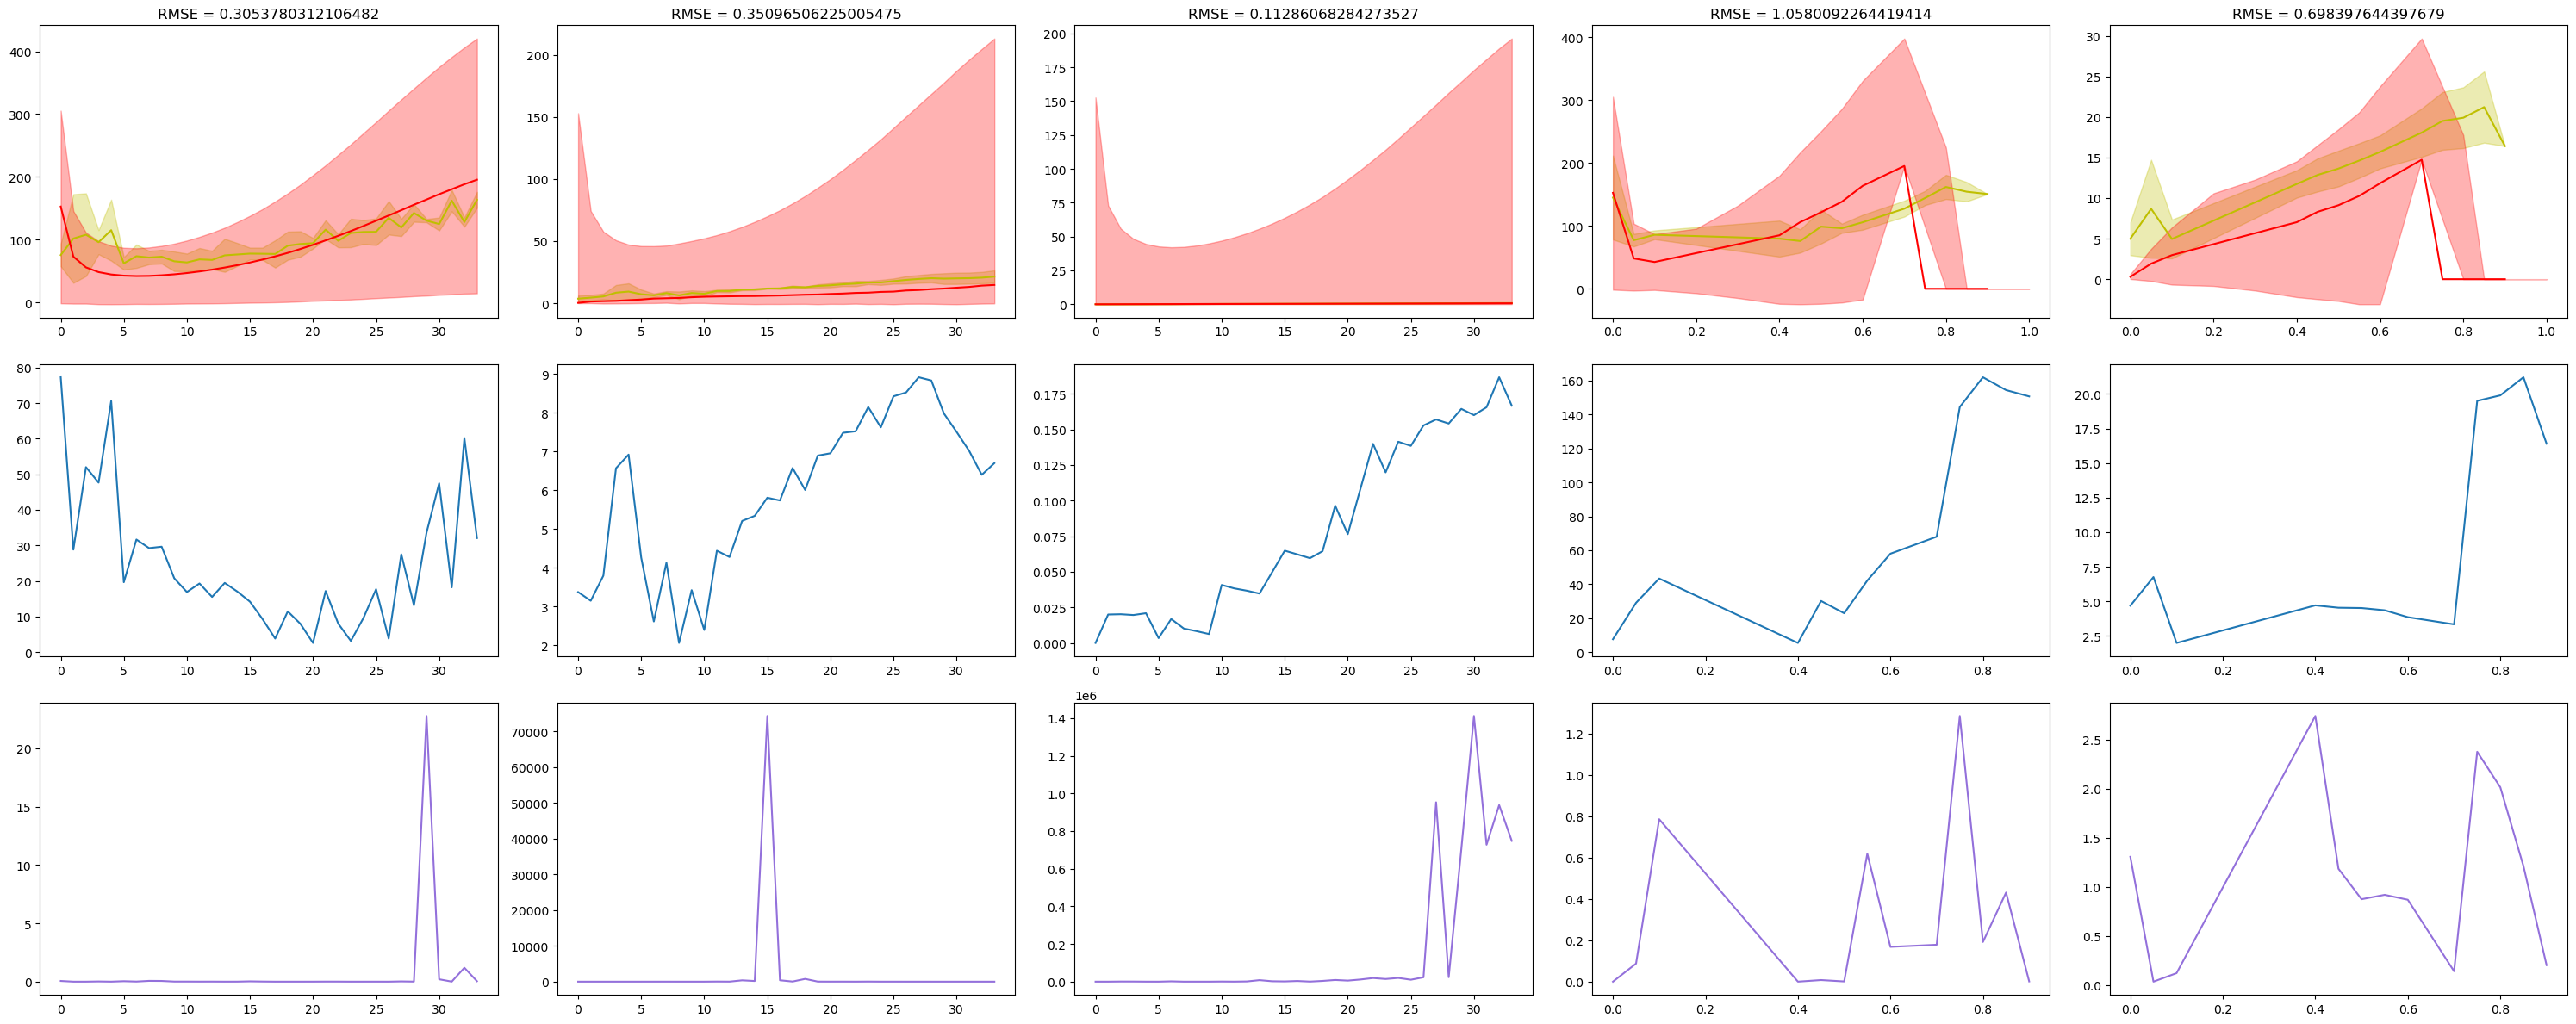

In [20]:
su = sim_uncertainty(par_best, par_upper, par_lower, {'z': z, 'time': len(z[0]), 'plot': 1, 'mode' : slice(None)})

In [13]:
def fit_dis(par_dis, alpha, sim_name):
    '''
    par_dis = list of pareto distributions for each parameter and the calculated number of bins for the histogram [[distribution1, nbins1], ...].
    alpha = alpha for ks test fitting distributions.
    sim_name = name of simulation for labeling output file.
    '''
    par_names = ['alpha', 'beta', 'vd', 'sg', 'D']
    par_units = [r'$hr^{-1}$', r'$mmhr^{-1}$', r'$mmhr^{-1}$', r'$mmhr^{-1}$', r'$mm^{2}hr^{-1}$']
    lower = []
    upper = []
    d = len(par_dis)
    fig, ax = plt.subplots(1,d, figsize = (3 * d, 3))
    for i in range(d):
        pd = par_dis[i]
        data = pd[0]
        bins = pd[1]
        pval_best = 0
        common_dis = [stats.norm, stats.lognorm,  stats.chi2, stats.t, stats.gamma, stats.expon, stats.uniform]
        for cd in common_dis:
            # fitting each common distribution
            par_guess = cd.fit(data)
            ks_stat, pval = stats.kstest(data, cd.cdf, args = par_guess)
            if pval > pval_best:
                # saving best fit distribution
                pval_best = pval
                dis_best = cd
                par_best = par_guess
        x = np.linspace(min(data), max(data), 1000)
        pdf_best = dis_best.pdf(x, *par_best)
    
        lower.append(dis_best.ppf(alpha / 2, *par_best))
        upper.append(dis_best.ppf(1 - alpha / 2, *par_best))
        
        y_hist, x_hist, _ = ax[i].hist(data, bins, density=True)
        ax[i].plot(x, pdf_best)
        ax[i].vlines(lower[i], 0, y_hist.max(), linestyle = '--', color = 'r')
        ax[i].vlines(upper[i], 0, y_hist.max(), linestyle = '--', color = 'r')
        ax[i].set_title(par_names[i] + '(' + dis_best.name + ')')
        ax[i].set_xlabel(par_names[i] + ' value(' + par_units[i] + ')')

    fig.tight_layout()
    plt.savefig(sim_name + '_parameter_distributions.png')
    plt.show()
    return lower, upper

In [17]:
def round_to_signif(x, p):
    x = np.asarray(x)
    x_positive = np.where(np.isfinite(x) & (x != 0), np.abs(x), 10**(p-1))
    mags = 10 ** (p - 1 - np.floor(np.log10(x_positive)))
    return np.round(x * mags) / mags

In [20]:
XZ1 = round_to_signif(np.loadtxt('bmxfungi_AMALGAM/output_fungi_11_XZ1', delimiter=','), 2)
print(XZ1)

[[2.7e-01 7.7e-03 3.0e-02 8.5e-02 1.8e-04]
 [2.7e-01 7.7e-03 3.0e-02 8.5e-02 1.8e-04]
 [2.7e-01 7.7e-03 3.0e-02 8.5e-02 1.8e-04]
 ...
 [2.5e-01 1.9e-02 1.1e-02 3.4e-02 7.6e-05]
 [6.7e-01 1.6e-02 2.0e-03 1.3e-01 2.9e-04]
 [1.7e-01 6.5e-03 1.2e-02 3.9e-02 6.6e-05]]


In [21]:
par_dis = []
for i in range(5):
    data = XZ1[:, i]
    par_dis.append([data, int(np.sqrt(int(len(data))))])

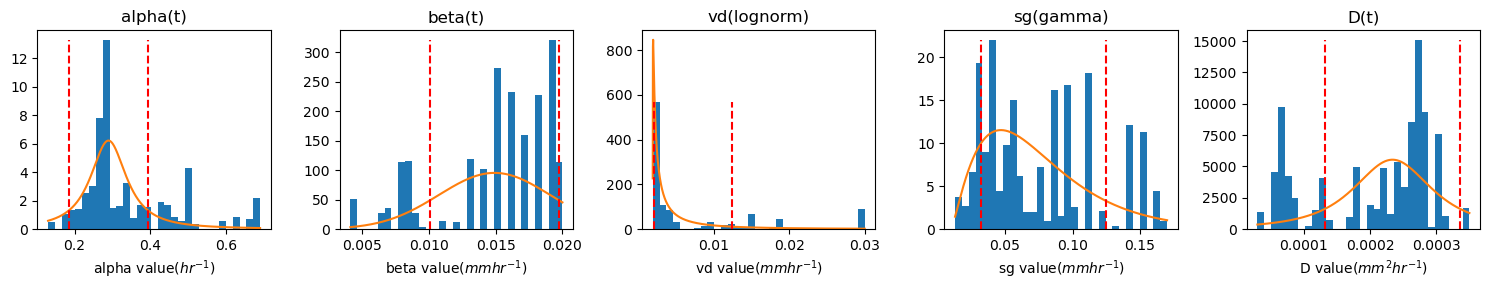

In [22]:
par_lower, par_upper = fit_dis(par_dis, 0.25, 'output_fungi_11')

In [66]:
par_lower

[np.float64(0.21051420778046454),
 np.float64(0.006570161300100116),
 np.float64(0.0025160989052740437),
 np.float64(0.03284809886870904),
 np.float64(7.290520254299967e-05)]

In [67]:
par_upper

[np.float64(0.3907538684270005),
 np.float64(0.020206076911684932),
 np.float64(0.02648594758113887),
 np.float64(0.10963615378271452),
 np.float64(0.0002758115687871187)]

In [58]:
Xf = np.loadtxt("output_fungi_11_Xf", delimiter=',')

In [59]:
par_dis = []
for i in range(5):
    data = Xf[:, i]
    par_dis.append([data, int(np.sqrt(int(len(data))))])

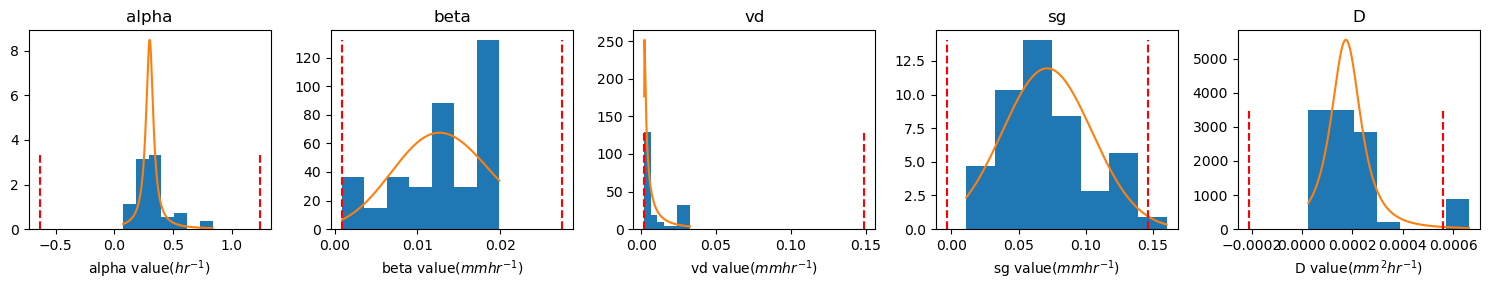

In [60]:
par_lower, par_upper = fit_dis(par_dis, 0.025, 'output_fungi_11')

In [43]:
par_lower

[np.float64(-0.6357680507484311),
 np.float64(0.0008774338718374047),
 np.float64(0.0020476498348136205),
 np.float64(-0.0035668659108349376),
 np.float64(-0.00021064250762152845)]

In [44]:
par_upper

[np.float64(1.2370361269558996),
 np.float64(0.027478380434319077),
 np.float64(0.14897047221552873),
 np.float64(0.14605111856225855),
 np.float64(0.0005593592789516475)]

In [63]:
j = 0
for par in par_lower:
    if par <= 0:
        par_lower[j] = np.min(Xf[:, j])
    j += 1

In [64]:
par_lower

[np.float64(0.07497032481763621),
 np.float64(0.0008774338718374047),
 np.float64(0.0020476498348136205),
 np.float64(0.011015916253564143),
 np.float64(2.4973155133472352e-05)]

In [81]:
N = 50
d = 5
p_min = (1 / 10) * np.array(par_upper)    # Minimum parameter values
p_max = 5 * np.array(par_upper) 
seed = np.array([par_lower])

In [84]:
N_rand = N - 1 # AMALGAMPar['m'] # rest of the population is random
X_rand = p_min + np.random.rand(N_rand, d) * (p_max - p_min)
X = np.append(X_rand, seed, axis=0)

In [79]:
np.shape(X_rand)

(49, 5)

In [82]:
np.shape(seed)

(1, 5)

In [85]:
np.shape(X)

(50, 5)

In [86]:
X[N - 1:, :]

array([[2.10514208e-01, 6.57016130e-03, 2.51609891e-03, 3.28480989e-02,
        7.29052025e-05]])

In [87]:
seed

array([[2.10514208e-01, 6.57016130e-03, 2.51609891e-03, 3.28480989e-02,
        7.29052025e-05]])